<center><h1>HW5</h1></center>
<br>
<br>

Name: Naveed Alboudwarej
<br>
USC ID: 8695198359

## 1. Decision Trees as Interpretable Models

Import packages

In [32]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.pyplot import subplots
import sklearn.linear_model as skl
import sklearn.model_selection as skm
from sklearn.tree import DecisionTreeClassifier as DTC,plot_tree,export_text
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [33]:
column= ["temp","nausea","lumbar_pain","urine_pushing","micturition_pain","burning","bladder","nephritis"]
df= pd.read_csv("diagnosis.data",sep= "\t",header= None,names= column,encoding= "utf-16",decimal= ",")
df[column[1:]]= (df[column[1:]]=="yes").astype(int)
print(df.head())

   temp  nausea  lumbar_pain  urine_pushing  micturition_pain  burning  \
0  35.5       0            1              0                 0        0   
1  35.9       0            0              1                 1        1   
2  35.9       0            1              0                 0        0   
3  36.0       0            0              1                 1        1   
4  36.0       0            1              0                 0        0   

   bladder  nephritis  
0        0          0  
1        1          0  
2        0          0  
3        1          0  
4        0          0  


### (b) Build a decision tree

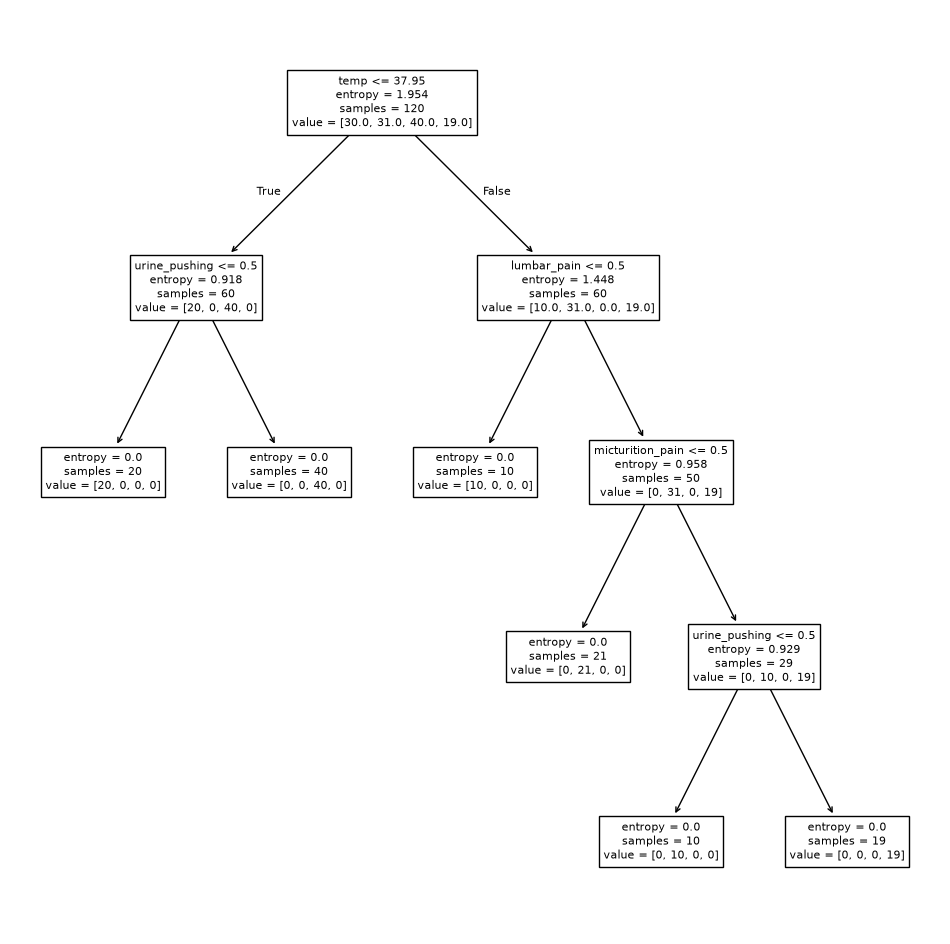

In [34]:
x= df.drop(columns= ["bladder","nephritis"])
y= df["bladder"]*2+df["nephritis"]
clf= DTC(criterion= "entropy",random_state= 0)
clf.fit(x,y)
fig,ax= subplots(figsize=(12,12))
plot_tree(clf,feature_names= x.columns,ax= ax);

Bladder and nephritis were combined into one 4-class label (0 = neither, 1 = nephritis only, 2 = bladder only, 3 = both). The tree has 6 leaves and splits first on temp (37.95). Every leaf is pure, so all 120 rows are classified correctly.

### (c) Convert the decision rules

In [35]:
print(export_text(clf,feature_names= x.columns))

|--- temp <= 37.95
|   |--- urine_pushing <= 0.50
|   |   |--- class: 0
|   |--- urine_pushing >  0.50
|   |   |--- class: 2
|--- temp >  37.95
|   |--- lumbar_pain <= 0.50
|   |   |--- class: 0
|   |--- lumbar_pain >  0.50
|   |   |--- micturition_pain <= 0.50
|   |   |   |--- class: 1
|   |   |--- micturition_pain >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: 3



The tree gives 6 IF-THEN rules:
- IF temp <= 37.95 AND urine_pushing = no THEN class 0
- IF temp <= 37.95 AND urine_pushing = yes THEN class 2
- IF temp > 37.95 AND lumbar_pain = no THEN class 0
- IF temp > 37.95 AND lumbar_pain = yes AND micturition_pain = no THEN class 1
- IF temp > 37.95 AND lumbar_pain = yes AND micturition_pain = yes AND urine_pushing = no THEN class 1
- IF temp > 37.95 AND lumbar_pain = yes AND micturition_pain = yes AND urine_pushing = yes THEN class 3

### 1.4 (d) Cost-complexity pruning

|--- temp <= 37.95
|   |--- urine_pushing <= 0.50
|   |   |--- class: 0
|   |--- urine_pushing >  0.50
|   |   |--- class: 2
|--- temp >  37.95
|   |--- lumbar_pain <= 0.50
|   |   |--- class: 0
|   |--- lumbar_pain >  0.50
|   |   |--- micturition_pain <= 0.50
|   |   |   |--- class: 1
|   |   |--- micturition_pain >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: 3



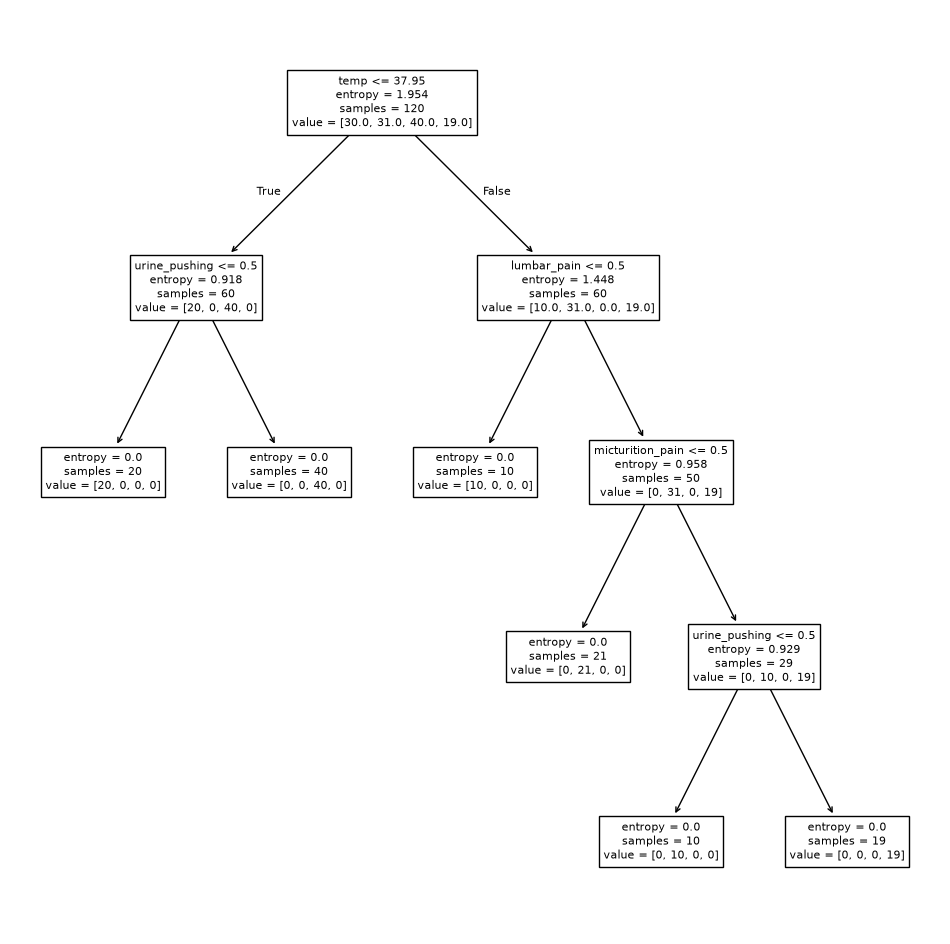

In [36]:
ccp_path= clf.cost_complexity_pruning_path(x,y)
kfold= skm.KFold(10,random_state= 1,shuffle= True)
grid= skm.GridSearchCV(clf,{"ccp_alpha":ccp_path.ccp_alphas},cv= kfold)
grid.fit(x,y)
best_= grid.best_estimator_
fig,ax= subplots(figsize=(12,12))
plot_tree(best_,feature_names= x.columns,ax= ax);
print(export_text(best_,feature_names= x.columns))

Cross-validation chose α= 0, so nothing was pruned. The CV accuracy was 1.0 at α= 0 and got worse for every larger α. The tree is the same 6-leaf tree as in (c).

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [37]:
with open("communities.names") as f:
    names= [line.replace("@attribute","").split()[0] for line in f if line.startswith("@attribute")]
data= pd.read_csv("communities.data",header= None,names= names,na_values= ["?"])
train= data.iloc[:1495]
test= data.iloc[1495:]
print(train.shape,test.shape)

(1495, 128) (499, 128)


The training set has 1495 rows and the test set has 499 rows, each with 128 columns.

### (b) Missing values

In [38]:
drop_list= ["state","county","community","communityname","fold"]
train= train[train.columns.drop(drop_list)]
test= test[test.columns.drop(drop_list)]
mean= train.mean()
train= train.fillna(mean)
test= test.fillna(mean)

### (c) Plot a correlation matrix

<Axes: >

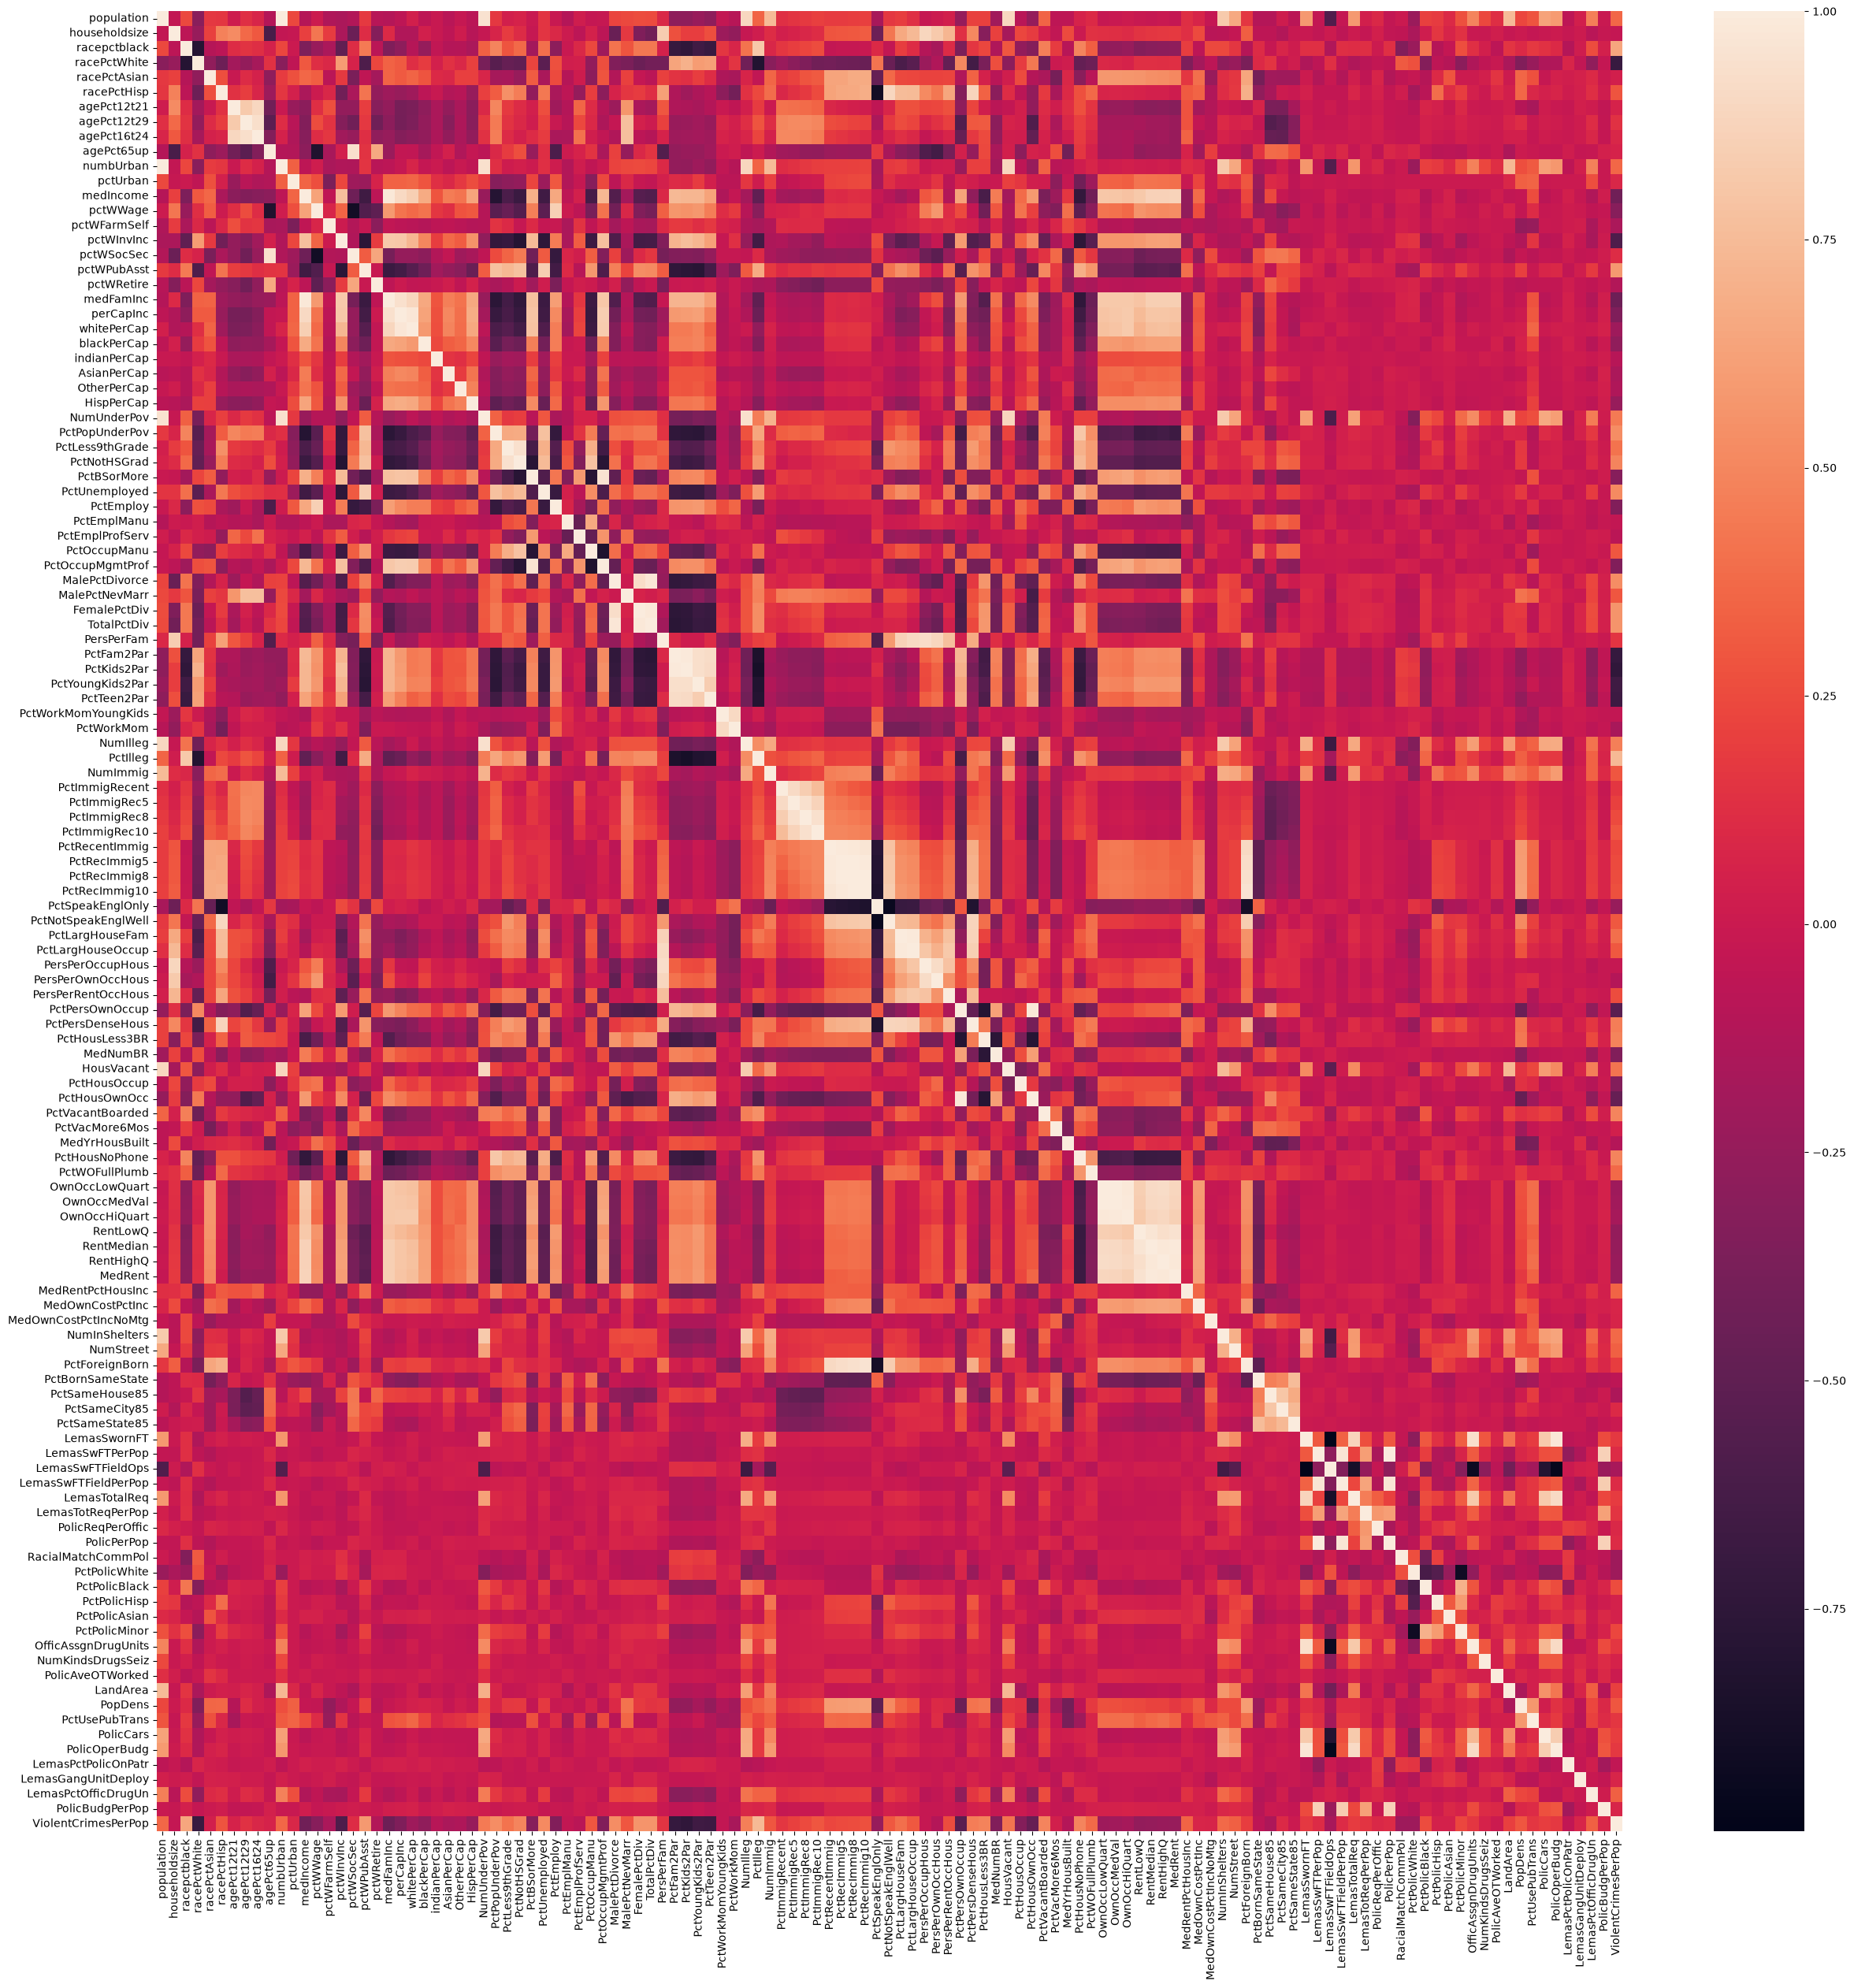

In [39]:
fig,ax= subplots(figsize=(30,30))
sns.heatmap(train.corr(),xticklabels= True,yticklabels= True,ax= ax)

Among the 122 features, only about 2% of the pairs (152 of 7381) have a correlation above 0.8 in absolute value, and these show up as small dark groups in the plot. The response ViolentCrimesPerPop is most correlated with PctIlleg (0.74) and PctKids2Par (-0.74).

### (d) Calculate the Coefficient of Variation CV

In [40]:
x_train= train[train.columns.drop("ViolentCrimesPerPop")]
cv= np.std(x_train,axis= 0,ddof= 1)/np.mean(x_train,axis= 0)
print(cv)

population             2.241105
householdsize          0.355800
racepctblack           1.428885
racePctWhite           0.330213
racePctAsian           1.359100
                         ...   
PolicOperBudg          0.743487
LemasPctPolicOnPatr    0.115739
LemasGangUnitDeploy    0.362989
LemasPctOfficDrugUn    2.552946
PolicBudgPerPop        0.326026
Length: 122, dtype: float64


The CV ranges from 0.06 (LemasSwFTFieldOps) to 4.29 (NumStreet) across the 122 features.

### (e) Scatter plots and box plots for highest CV features

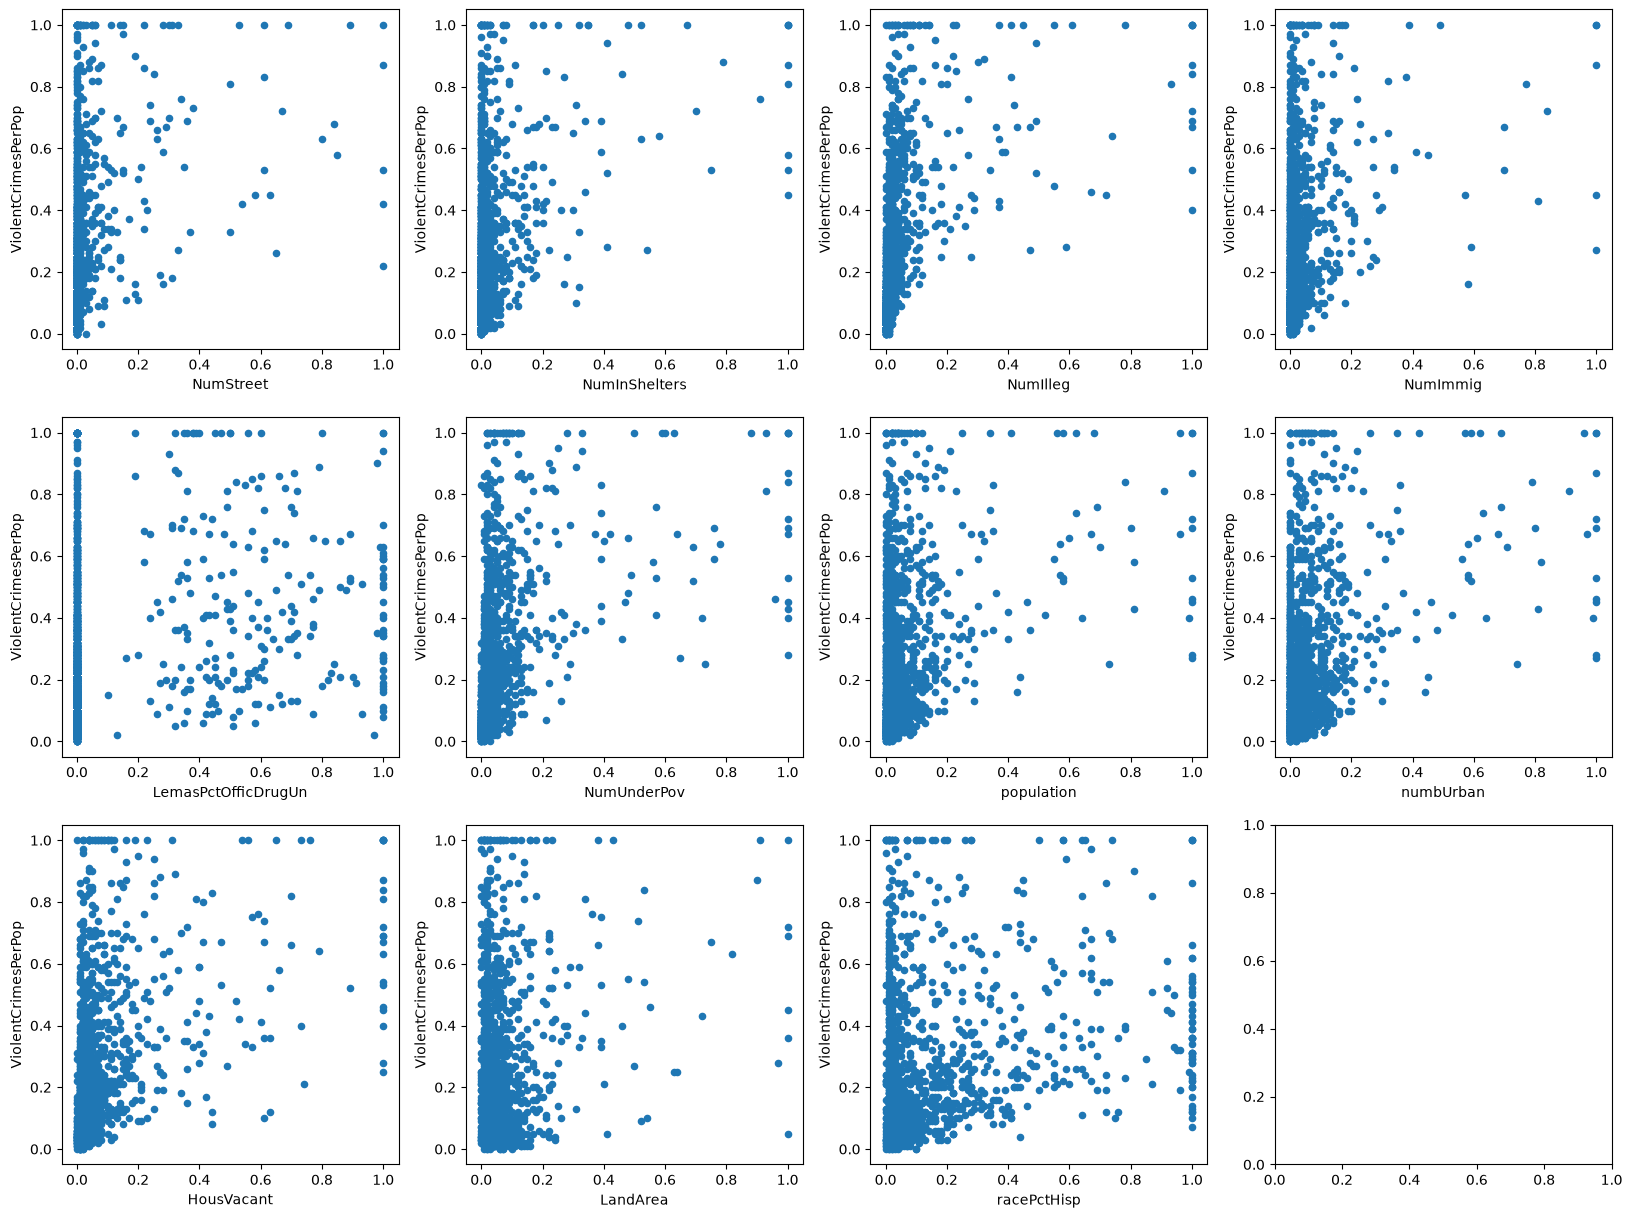

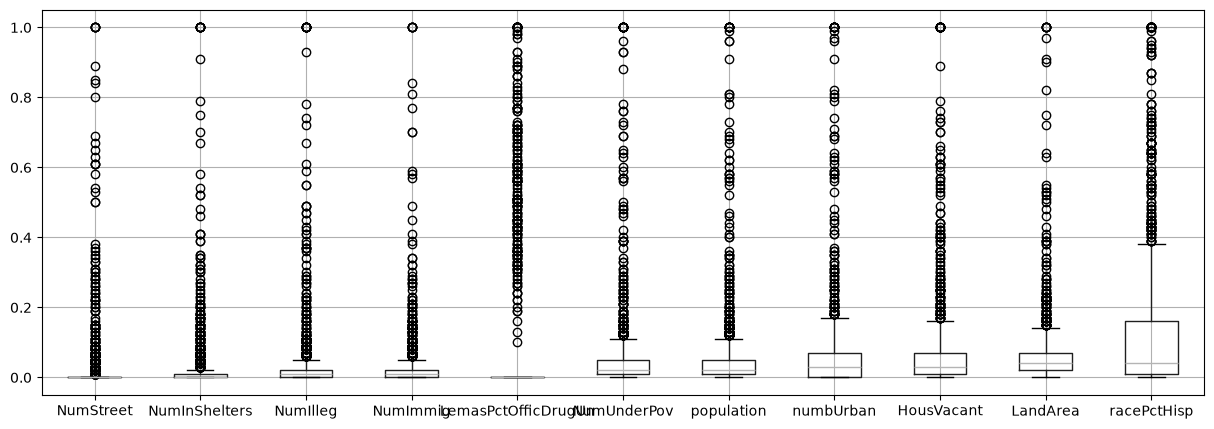

In [41]:
top= cv.nlargest(int(np.sqrt(128))).index
fig,axes= subplots(nrows= 3,ncols= 4,figsize= (20,15))
for name,ax in zip(top,axes.flat):
    train.plot.scatter(name,"ViolentCrimesPerPop",ax= ax)
fig,ax= subplots(figsize= (15,5))
x_train[top].boxplot(ax= ax);

The 11 features with the highest CV are NumStreet, NumInShelters, NumIlleg, NumImmig, LemasPctOfficDrugUn, NumUnderPov, population, numbUrban, HousVacant, LandArea and racePctHisp.

No, we cannot conclude significance from the scatter plots. Most points are bunched near 0 and the trends are weak and noisy.

### (f) Fit a linear model

In [42]:
x_test= test[test.columns.drop("ViolentCrimesPerPop")]
y_train= train["ViolentCrimesPerPop"]
y_test= test["ViolentCrimesPerPop"]
linreg= skl.LinearRegression()
linreg.fit(x_train,y_train)
print(mean_squared_error(y_test,linreg.predict(x_test)))

0.018141971135530094


The test MSE of the least-squares model is 0.0181. This is the baseline for the next models.

### (g) Fit a ridge regression model

In [43]:
lambdas= 10**np.linspace(8,-6,100)
kfold= skm.KFold(5,random_state= 0,shuffle= True)
ridgeCV= skl.ElasticNetCV(alphas= lambdas,l1_ratio= 0,cv= kfold)
ridgeCV.fit(x_train,y_train)
print("Test MSE =",mean_squared_error(y_test,ridgeCV.predict(x_test)))
print("Chosen lambda =",ridgeCV.alpha_)

Test MSE = 0.017579048997810695
Chosen lambda = 0.001788649529057435


Ridge with λ chosen by 5-fold CV (λ= 0.0018) has a test MSE of 0.0176, a little lower than least squares.

### (h) Fit a LASSO model

In [44]:
lassoCV= skl.ElasticNetCV(l1_ratio= 1,cv= kfold,max_iter= 10000)
lassoCV.fit(x_train,y_train)
print("Test MSE =",mean_squared_error(y_test,lassoCV.predict(x_test)))
print("Number of selected features =",(lassoCV.coef_ != 0).sum())
print("Selected features:")
for name in x_train.columns[lassoCV.coef_ != 0]:
    print(name)

Test MSE = 0.0178226153235115
Number of selected features = 80
Selected features:
racepctblack
racePctAsian
agePct12t21
agePct12t29
agePct65up
pctUrban
pctWWage
pctWFarmSelf
pctWInvInc
pctWSocSec
pctWPubAsst
pctWRetire
medFamInc
whitePerCap
blackPerCap
indianPerCap
AsianPerCap
OtherPerCap
HispPerCap
PctPopUnderPov
PctLess9thGrade
PctBSorMore
PctEmploy
PctEmplManu
PctOccupManu
MalePctDivorce
MalePctNevMarr
FemalePctDiv
PctKids2Par
PctYoungKids2Par
PctTeen2Par
PctWorkMomYoungKids
PctWorkMom
NumIlleg
PctIlleg
NumImmig
PctImmigRec10
PctRecImmig10
PctNotSpeakEnglWell
PctLargHouseOccup
PersPerOccupHous
PersPerOwnOccHous
PctPersOwnOccup
PctPersDenseHous
PctHousLess3BR
MedNumBR
HousVacant
PctHousOccup
PctVacantBoarded
PctVacMore6Mos
MedYrHousBuilt
PctHousNoPhone
PctWOFullPlumb
OwnOccLowQuart
RentLowQ
MedRent
MedRentPctHousInc
MedOwnCostPctInc
MedOwnCostPctIncNoMtg
NumInShelters
NumStreet
PctForeignBorn
PctSameCity85
LemasSwFTFieldPerPop
LemasTotalReq
PolicReqPerOffic
RacialMatchCommPol
PctPoli

LASSO with λ chosen by CV has a test MSE of 0.0178 and keeps 80 of the 122 features. The other 42 have a coefficient of exactly 0. The kept features are listed above.

In [45]:
scaler= StandardScaler(with_mean= True,with_std= True)
lassoCV= skl.ElasticNetCV(l1_ratio= 1,cv= kfold,max_iter= 10000)
pipeCV= Pipeline(steps= [("scaler",scaler),("lasso",lassoCV)])
pipeCV.fit(x_train,y_train)
print("Test MSE =",mean_squared_error(y_test,pipeCV.predict(x_test)))
print("Number of selected features =",(lassoCV.coef_ != 0).sum())
print("Selected features:")
for name in x_train.columns[lassoCV.coef_ != 0]:
    print(name)

Test MSE = 0.017839043673251096
Number of selected features = 76
Selected features:
population
racepctblack
racePctAsian
agePct12t21
agePct12t29
pctUrban
pctWWage
pctWFarmSelf
pctWInvInc
pctWSocSec
pctWPubAsst
pctWRetire
whitePerCap
blackPerCap
indianPerCap
AsianPerCap
OtherPerCap
HispPerCap
PctPopUnderPov
PctLess9thGrade
PctEmploy
PctEmplManu
PctOccupManu
MalePctDivorce
MalePctNevMarr
FemalePctDiv
PctKids2Par
PctYoungKids2Par
PctTeen2Par
PctWorkMom
NumIlleg
PctIlleg
NumImmig
PctImmigRec10
PctRecImmig10
PctNotSpeakEnglWell
PctLargHouseOccup
PersPerOccupHous
PctPersOwnOccup
PctPersDenseHous
PctHousLess3BR
MedNumBR
HousVacant
PctHousOccup
PctVacantBoarded
PctVacMore6Mos
MedYrHousBuilt
PctHousNoPhone
PctWOFullPlumb
OwnOccLowQuart
RentLowQ
MedRent
MedRentPctHousInc
MedOwnCostPctInc
MedOwnCostPctIncNoMtg
NumInShelters
NumStreet
PctForeignBorn
PctSameCity85
LemasSwFTFieldPerPop
LemasTotalReq
PolicReqPerOffic
RacialMatchCommPol
PctPolicWhite
PctPolicBlack
PctPolicHisp
PctPolicAsian
OfficAssgn

With standardized features the test MSE is 0.0178 again and 76 features are kept. Standardizing barely changes the result because the features were already normalized.

### (i) Fit a PCR model

In [46]:
pipe= Pipeline([("pca",PCA()),("linreg",skl.LinearRegression())])
param_grid= {"pca__n_components": range(1,123)}
grid= skm.GridSearchCV(pipe,param_grid,cv= kfold,scoring= "neg_mean_squared_error")
grid.fit(x_train,y_train)
print("Test MSE =",mean_squared_error(y_test,grid.predict(x_test)))
print("Chosen M =",grid.best_params_["pca__n_components"])

Test MSE = 0.018471778516167773
Chosen M = 96


PCR with M chosen by CV uses 96 of the 122 principal components. The test MSE is 0.0185, the highest of the models so far.

### (j) Fit a boosting tree

In [47]:
param_grid= {"reg_alpha": [0,0.001,0.01,0.1,1,10,100]}
grid= skm.GridSearchCV(XGBRegressor(),param_grid,cv= kfold,scoring= "neg_mean_squared_error")
grid.fit(x_train,y_train)
print("Test MSE =",mean_squared_error(y_test,grid.predict(x_test)))
print("Chosen alpha =",grid.best_params_["reg_alpha"])

Test MSE = 0.017747461401957192
Chosen alpha = 1


α is XGBoost's L1 penalty (reg_alpha). The values tried were 0 and every power of 10 from 0.001 to 100, and CV chose α= 1. It falls inside that range, with worse values on both sides.